# 1. Данные, качество данных и разведочный анализ (EDA)

**Проект:** подбор автомобилей и оценка рыночной цены на основе машинного обучения.

**Источник:** открытый датасет [Cars for sale in Moldova](https://www.kaggle.com/datasets/alexandrududa/cars-moldova) (Kaggle, лицензия CC0) — объявления о продаже автомобилей с сайта 999.md, 2021 год. Датасет скачивается через публичный Kaggle API и загружается в базу данных (SQLite; PostgreSQL — через `DATABASE_URL`).

Пайплайн данных: `python -m car_advisor.data.download` → `python -m car_advisor.data.database` → `python -m car_advisor.data.quality`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from car_advisor import config, viz
viz.use_matplotlib_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1.1 Подключение к базе данных

Читаем сырые объявления из таблицы `listings_raw` через SQLAlchemy.

In [2]:
from sqlalchemy import inspect as sa_inspect
from car_advisor.data import database as db

engine = db.get_engine()
print("БД:", engine.url.render_as_string(hide_password=True).split("/")[-1], "| таблицы:", sa_inspect(engine).get_table_names())
raw = db.read_table("listings_raw")
print(f"Сырых объявлений: {len(raw):,}")
raw.head()

БД: cars.db | таблицы: ['listings', 'listings_raw', 'quality_issues']
Сырых объявлений: 41,007


,id,make,model,year,style,distance_km,engine_cc,fuel_type,transmission,price_eur,loaded_at
0,1,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,Automatic,7750.0,2026-10-06 13:57:00
1,2,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,Manual,8550.0,2026-10-06 13:57:00
2,3,Volkswagen,Golf,1998,Hatchback,1.0,1400.0,Petrol,Manual,2200.0,2026-10-06 13:57:00
3,4,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,Manual,6550.0,2026-10-06 13:57:00
4,5,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,Manual,4100.0,2026-10-06 13:57:00


## 1.2 Профиль данных

In [3]:
raw.info()
raw.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T.round(1)

<class 'pandas.DataFrame'>
RangeIndex: 41007 entries, 0 to 41006
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            41007 non-null  int64         
 1   make          41007 non-null  str           
 2   model         41007 non-null  str           
 3   year          41007 non-null  int64         
 4   style         41007 non-null  str           
 5   distance_km   41007 non-null  float64       
 6   engine_cc     41007 non-null  float64       
 7   fuel_type     41007 non-null  str           
 8   transmission  41007 non-null  str           
 9   price_eur     41007 non-null  float64       
 10  loaded_at     41007 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2), str(5)
memory usage: 4.7 MB


,count,mean,min,1%,5%,50%,95%,99%,max,std
id,41007.0,20504.0,1.0,411.06,2051.3,20504.0,38956.7,40596.94,41007.0,11837.845581
year,41007.0,2007.976175,1900.0,1986.0,1993.0,2009.0,2018.0,2020.0,2021.0,8.241487
distance_km,41007.0,456735.302387,0.0,0.0,20.3,168000.0,350000.0,1959873.76,100000000.0,4451897.349615
engine_cc,41007.0,1853.856732,0.0,100.0,1199.0,1800.0,3000.0,4400.0,9999.0,700.364532
price_eur,41007.0,9727.109079,1.0,600.0,1200.0,6600.0,26500.0,49900.0,10000000.0,50439.26102
loaded_at,41007,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,2026-10-06 13:57:00,NaN


In [4]:
print("Пропусков по колонкам:"); print(raw.isna().sum().to_string())
dups = raw.duplicated(subset=db.LISTING_COLUMNS).sum()
print(f"\nТочных дубликатов: {dups:,} ({dups / len(raw):.1%})")
for col in ["make", "model", "style", "fuel_type", "transmission"]:
    print(f"{col:13s}: {raw[col].nunique():4d} уникальных значений")

Пропусков по колонкам:
id              0
make            0
model           0
year            0
style           0
distance_km     0
engine_cc       0
fuel_type       0
transmission    0
price_eur       0
loaded_at       0

Точных дубликатов: 3,743 (9.1%)
make         :   87 уникальных значений
model        :  829 уникальных значений
style        :   12 уникальных значений
fuel_type    :    6 уникальных значений
transmission :    2 уникальных значений


## 1.3 Проблемы качества

Смотрим на подозрительные значения: заглушки года и пробега, невозможные пробеги, объём двигателя «в литрах × 100», экстремальные цены.

In [5]:
age = config.SNAPSHOT_YEAR - raw["year"]
checks = {
    "Год выпуска 1900 (заглушка)": (raw["year"] == 1900).sum(),
    "Пробег 0–1 км": raw["distance_km"].isin([0, 1]).sum(),
    "Пробег < 1000 км у авто старше 3 лет": ((raw["distance_km"] < 1000) & (age >= 3)).sum(),
    "Пробег > 1 000 000 км": (raw["distance_km"] > 1_000_000).sum(),
    "Объём двигателя 90–500 см³ (не электро)": (raw["engine_cc"].between(90, 499) & (raw["fuel_type"] != "Electric")).sum(),
    "Цена < 300 €": (raw["price_eur"] < 300).sum(),
    "Цена > 250 000 €": (raw["price_eur"] > 250_000).sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
Год выпуска 1900 (заглушка),30
Пробег 0–1 км,1698
Пробег < 1000 км у авто старше 3 лет,3539
Пробег > 1 000 000 км,623
Объём двигателя 90–500 см³ (не электро),957
Цена < 300 €,23
Цена > 250 000 €,2


In [6]:
print("Самые частые «маленькие» значения пробега:")
print(raw.loc[raw["distance_km"] < 1000, "distance_km"].value_counts().head(8).to_string())
print("\nПримеры объёма двигателя 200 «см³» — на деле 2.0 л:")
raw[(raw["engine_cc"] == 200) & (raw["fuel_type"] != "Electric")][["make", "model", "year", "engine_cc", "fuel_type", "price_eur"]].head(6)

Самые частые «маленькие» значения пробега:
distance_km
1.0      867
0.0      831
300.0    138
200.0    124
111.0    120
2.0       98
100.0     75
10.0      62

Примеры объёма двигателя 200 «см³» — на деле 2.0 л:


,make,model,year,engine_cc,fuel_type,price_eur
38,Volkswagen,Touran,2004,200.0,Diesel,5300.0
167,Hyundai,Tucson,2014,200.0,Metan/Propan,12000.0
222,Mazda,626,1994,200.0,Metan/Propan,18000.0
290,Citroen,Berlingo,2004,200.0,Diesel,2000.0
291,BMW,X3,2009,200.0,Diesel,11000.0
319,Toyota,Avensis,2005,200.0,Petrol,5300.0


Видно, что `200` — это 2.0 л (BMW 5 Series, Toyota Previa, Mercedes E-Class), поэтому такие значения **исправляются** (× 10), а не удаляются. Экстремальные цены (например, 490 000 € за KIA Sportage 2018) — вероятно, цены в леях: их ловит групповое правило «цена отличается от медианы марки/модели/года более чем в 3 раза».

## 1.4 Результат очистки

Правила реализованы в `car_advisor/data/quality.py`; журнал проблем по каждой строке хранится в таблице `quality_issues`.

In [7]:
import json
report = json.loads(config.QUALITY_REPORT_JSON.read_text(encoding="utf-8"))
rules = pd.DataFrame(report["rules"])[["title", "action", "count"]]
print(f"Было {report['rows_raw']:,} → стало {report['rows_clean']:,} ({report['rows_clean'] / report['rows_raw']:.1%}); "
      f"в БД для обучения {report['rows_market']:,}, отложено как «новые» {report['rows_holdout']:,}")
rules

Было 41,007 → стало 32,945 (80.3%); в БД для обучения 31,298, отложено как «новые» 1,647


,title,action,count
0,Пропуски в обязательных полях,drop,0
1,Недопустимое значение категории (топливо/КПП/к...,drop,0
2,Точный дубликат объявления,drop,3743
3,Объём двигателя указан в литрах×100 (200 → 200...,repair,915
4,Объём двигателя у электромобиля (обнулён),repair,120
5,Год выпуска вне диапазона 1980–2021,drop,141
6,"Цена вне диапазона 300–250,000 €",drop,25
7,"Пробег больше 1,000,000 км",drop,582
8,Пробег < 1000 км у авто старше 3 лет (заглушка),drop,3230
9,Объём двигателя вне 500–7000 см³,drop,29


## 1.5 Разведочный анализ очищенных данных

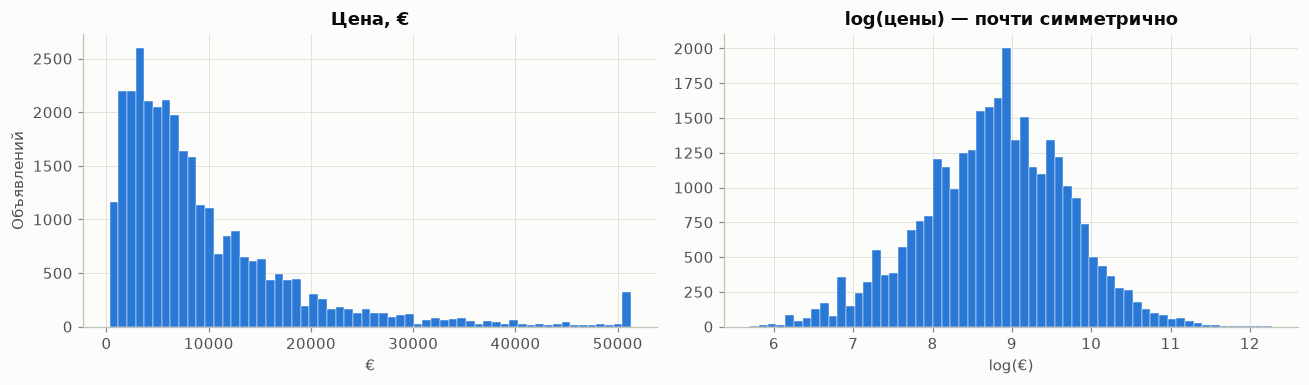

Асимметрия: цена 4.17, log(цены) -0.17 → модель будем обучать на log(цены)


In [8]:
df = db.read_table("listings")
df["age"] = df["listing_year"] - df["year"]
df["km_per_year"] = df["distance_km"] / (df["age"] + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(df["price_eur"].clip(upper=df["price_eur"].quantile(0.99)), bins=60, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
axes[0].set(title="Цена, €", xlabel="€", ylabel="Объявлений")
axes[1].hist(np.log(df["price_eur"]), bins=60, color=viz.SERIES[0], edgecolor=viz.SURFACE, linewidth=0.3)
axes[1].set(title="log(цены) — почти симметрично", xlabel="log(€)")
plt.tight_layout(); plt.show()
print(f"Асимметрия: цена {df['price_eur'].skew():.2f}, log(цены) {np.log(df['price_eur']).skew():.2f} → модель будем обучать на log(цены)")

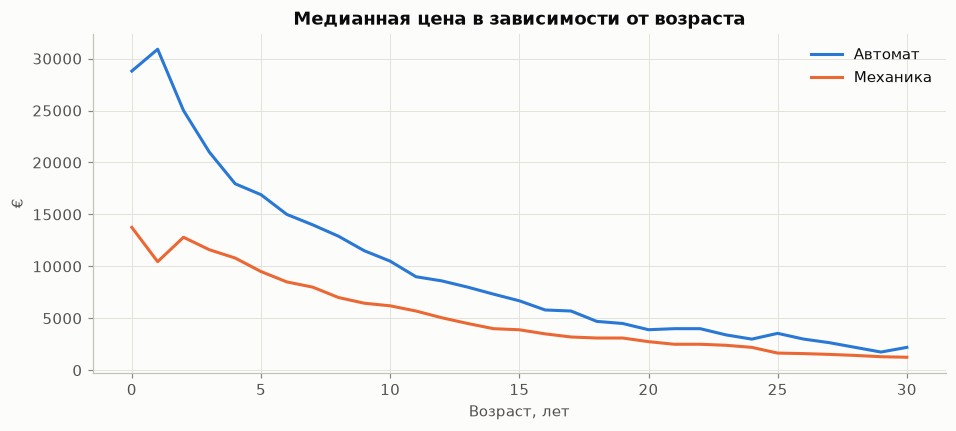

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, (trans, label) in enumerate([("Automatic", "Автомат"), ("Manual", "Механика")]):
    s = df[(df["transmission"] == trans) & (df["age"] <= 30)].groupby("age")["price_eur"].median()
    ax.plot(s.index, s.values, color=viz.SERIES[i], linewidth=2, label=label)
ax.set(title="Медианная цена в зависимости от возраста", xlabel="Возраст, лет", ylabel="€")
ax.legend(); plt.show()

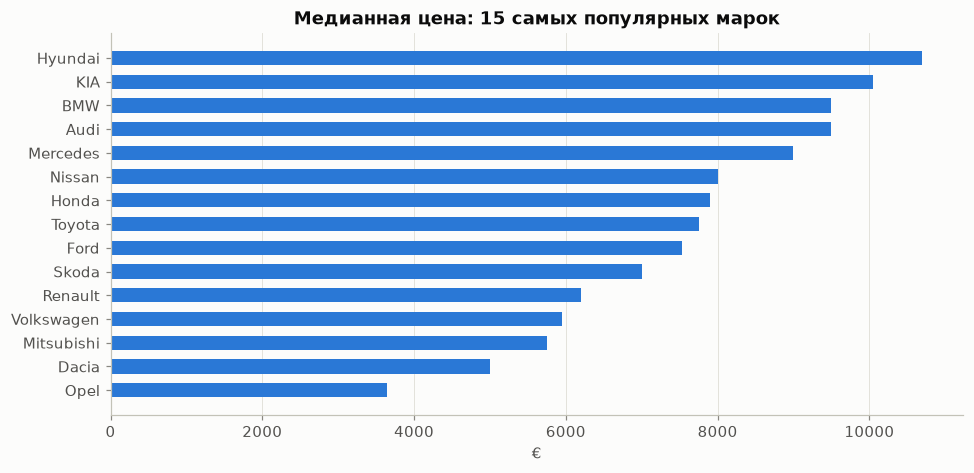

In [10]:
top = df["make"].value_counts().head(15).index
stats = df[df["make"].isin(top)].groupby("make")["price_eur"].agg(["median", "size"]).sort_values("median")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(stats.index, stats["median"], color=viz.SERIES[0], height=0.6)
ax.set(title="Медианная цена: 15 самых популярных марок", xlabel="€"); ax.grid(axis="y", visible=False)
plt.show()

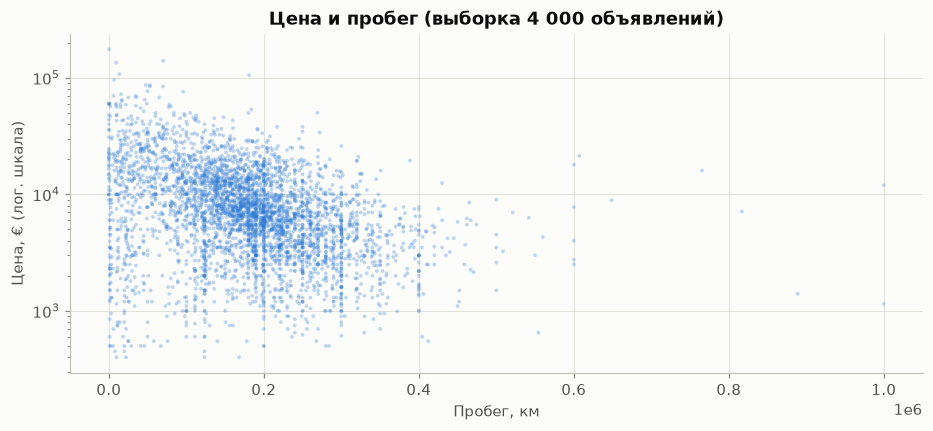

In [11]:
sample = df.sample(4000, random_state=config.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(sample["distance_km"], sample["price_eur"], s=6, alpha=0.3, color=viz.SERIES[0], edgecolors="none")
ax.set(yscale="log", title="Цена и пробег (выборка 4 000 объявлений)", xlabel="Пробег, км", ylabel="Цена, € (лог. шкала)")
plt.show()

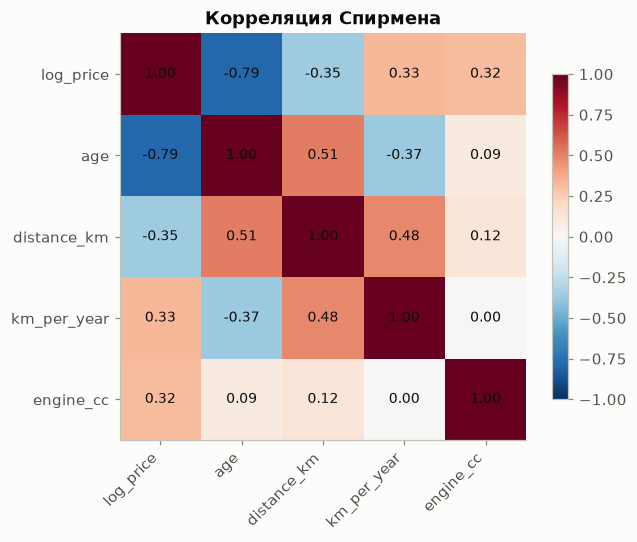

In [12]:
num = df.assign(log_price=np.log(df["price_eur"]))[["log_price", "age", "distance_km", "km_per_year", "engine_cc"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False); ax.set_title("Корреляция Спирмена"); fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

In [13]:
summary = pd.concat({
    "доля": df["fuel_type"].value_counts(normalize=True).round(3),
    "медианная цена, €": df.groupby("fuel_type")["price_eur"].median(),
    "медианный возраст": df.groupby("fuel_type")["age"].median(),
}, axis=1).sort_values("доля", ascending=False)
summary

,доля,"медианная цена, €",медианный возраст
fuel_type,,,
Diesel,0.467,7300.0,10.0
Petrol,0.347,5699.0,13.0
Metan/Propan,0.108,3999.0,16.0
Hybrid,0.056,12499.0,7.0
Plug-in Hybrid,0.014,14174.5,6.0
Electric,0.008,13000.0,5.0


## 1.6 Препроцессинг: признаки для модели

По выводам EDA поля объявления преобразуются в признаки (`car_advisor/ml/features.py`):

* **возраст** = год объявления − год выпуска (вместо календарного года);
* **модель** = «марка + модель», чтобы одинаковые названия у разных марок не смешивались;
* **пробег в год** — интенсивность эксплуатации.

In [14]:
from car_advisor.ml.features import FeatureBuilder, CAT_FEATURES, NUM_FEATURES

X = FeatureBuilder().transform(df)
print(f"Категориальные признаки: {CAT_FEATURES}")
print(f"Числовые признаки: {NUM_FEATURES}")
print("Уникальных значений:", {c: X[c].nunique() for c in CAT_FEATURES})
X.head()

Категориальные признаки: ['make', 'model', 'style', 'fuel_type', 'transmission']
Числовые признаки: ['age', 'distance_km', 'engine_cc', 'km_per_year']
Уникальных значений: {'make': 86, 'model': 875, 'style': 12, 'fuel_type': 6, 'transmission': 2}


,make,model,style,fuel_type,transmission,age,distance_km,engine_cc,km_per_year
0,Toyota,Toyota Prius,Hatchback,Hybrid,Automatic,10.0,195000.0,1800.0,17727.272727
1,Renault,Renault Grand Scenic,Universal,Diesel,Manual,7.0,135000.0,1500.0,16875.000000
2,Renault,Renault Laguna,Universal,Diesel,Manual,9.0,110000.0,1500.0,11000.000000
3,Opel,Opel Astra,Universal,Metan/Propan,Manual,15.0,200000.0,1600.0,12500.000000
4,Mercedes,Mercedes Vito,Microvan,Diesel,Manual,21.0,300000.0,2200.0,13636.363636


## 1.7 Выводы

1. Данные **открытые и реальные**, но «грязные»: около 9% точных дубликатов, заглушки года и пробега, невозможные пробеги и цены, единицы измерения объёма двигателя «в литрах × 100». После проверок качества остаётся около 80% объявлений; 915 значений объёма двигателя исправлено, а не удалено.
2. Цена сильно скошена вправо — модель будем обучать на **log(цены)**, ошибки становятся относительными.
3. Главный фактор — **возраст**: медианная цена быстро падает в первые 10 лет и выходит на плато после ~20 лет. Автомобили с автоматической КПП в среднем заметно дороже (они моложе и чаще премиальные).
4. Марка и модель задают уровень цены (премиальные марки дороже при том же возрасте) — нужна обработка категориальных признаков с высокой кардинальностью (≈900 моделей).
5. Пробег коррелирует с возрастом, поэтому дополнительно строим признак **пробег в год** — интенсивность эксплуатации.
6. Ограничение: в данных нет состояния, комплектации и истории ДТП — это ограничивает достижимую точность.

## Следующий этап

* обучение и сравнение нескольких моделей (линейный бейзлайн, Random Forest, градиентный бустинг) на кросс-валидации;
* выбор модели по MAE/MAPE и проверка на отложенных «новых» объявлениях (`data/new/new_listings_holdout.csv`);
* объяснимость предсказаний (SHAP).